### Reading the Data

### Import libraries


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
play = pd.read_csv("players_fifa22.csv", low_memory=False)
print("Dataset shape:", play.shape)

Dataset shape: (19260, 90)


## Checking the Data

In [4]:
# Determining the no. of records in our dataset
play.shape

(19260, 90)

In [5]:
# Previewing the top of our dataset
play.head(10)

,ID,Name,FullName,Age,Height,Weight,PhotoUrl,Nationality,Overall,Potential,...,LMRating,CMRating,RMRating,LWBRating,CDMRating,RWBRating,LBRating,CBRating,RBRating,GKRating
0,158023,L. Messi,Lionel Messi,34,170,72,https://cdn.sofifa.com/players/158/023/22_60.png,Argentina,93,93,...,93,90,93,69,67,69,64,53,64,22
1,188545,R. Lewandowski,Robert Lewandowski,32,185,81,https://cdn.sofifa.com/players/188/545/22_60.png,Poland,92,92,...,87,83,87,67,69,67,64,63,64,22
2,20801,Cristiano Ronaldo,C. Ronaldo dos Santos Aveiro,36,187,83,https://cdn.sofifa.com/players/020/801/22_60.png,Portugal,91,91,...,89,81,89,66,62,66,63,56,63,23
3,231747,K. Mbappé,Kylian Mbappé,22,182,73,https://cdn.sofifa.com/players/231/747/22_60.png,France,91,95,...,92,84,92,70,66,70,66,57,66,21
4,200389,J. Oblak,Jan Oblak,28,188,87,https://cdn.sofifa.com/players/200/389/22_60.png,Slovenia,91,93,...,38,41,38,35,39,35,35,36,35,92
5,192985,K. De Bruyne,Kevin De Bruyne,30,181,70,https://cdn.sofifa.com/players/192/985/22_60.png,Belgium,91,91,...,91,91,91,82,83,82,78,72,78,24
6,190871,Neymar Jr,Neymar da Silva Santos Jr.,29,175,68,https://cdn.sofifa.com/players/190/871/22_60.png,Brazil,91,91,...,91,85,91,70,66,70,65,53,65,23
7,215914,N. Kanté,N'Golo Kanté,30,168,70,https://cdn.sofifa.com/players/215/914/22_60.png,France,90,90,...,82,85,82,88,90,88,88,87,88,23
8,202126,H. Kane,Harry Kane,27,188,89,https://cdn.sofifa.com/players/202/126/22_60.png,England,90,90,...,87,85,87,70,71,70,67,64,67,23
9,192448,M. ter Stegen,Marc-André ter Stegen,29,187,85,https://cdn.sofifa.com/players/192/448/22_60.png,Germany,90,92,...,42,48,42,36,44,36,34,36,34,91


## Data Validation


In [6]:
# Checking column names, data types, and non-null values
play.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19260 entries, 0 to 19259
Data columns (total 90 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID                 19260 non-null  int64  
 1   Name               19260 non-null  object 
 2   FullName           19260 non-null  object 
 3   Age                19260 non-null  int64  
 4   Height             19260 non-null  int64  
 5   Weight             19260 non-null  int64  
 6   PhotoUrl           19260 non-null  object 
 7   Nationality        19260 non-null  object 
 8   Overall            19260 non-null  int64  
 9   Potential          19260 non-null  int64  
 10  Growth             19260 non-null  int64  
 11  TotalStats         19260 non-null  int64  
 12  BaseStats          19260 non-null  int64  
 13  Positions          19260 non-null  object 
 14  BestPosition       19260 non-null  object 
 15  Club               19260 non-null  object 
 16  ValueEUR           192

In [7]:
# Checking missing values in each column
missing_values = play.isnull().sum()

missing_values[missing_values > 0].sort_values(ascending=False)


NationalPosition    18503
NationalNumber      18503
ClubPosition           76
ContractUntil          76
ClubNumber             76
dtype: int64

In [8]:
# Checking for duplicate player records
print("Duplicate rows:", play.duplicated().sum())

print("Duplicate player IDs:", play["ID"].duplicated().sum())

Duplicate rows: 104
Duplicate player IDs: 104


In [9]:
# Displaying summary statistics for numerical features
play.describe()

,ID,Age,Height,Weight,Overall,Potential,Growth,TotalStats,BaseStats,ValueEUR,...,LMRating,CMRating,RMRating,LWBRating,CDMRating,RWBRating,LBRating,CBRating,RBRating,GKRating
count,19260.000000,19260.000000,19260.000000,19260.000000,19260.000000,19260.000000,19260.000000,19260.000000,19260.000000,1.926000e+04,...,19260.000000,19260.000000,19260.000000,19260.000000,19260.000000,19260.000000,19260.000000,19260.000000,19260.000000,19260.000000
mean,231682.741952,25.184683,181.305036,74.950779,65.815628,71.100104,5.284476,1598.525909,357.062461,2.857652e+06,...,58.364434,57.227207,58.364434,56.197040,55.771340,56.197040,55.539823,54.379595,55.539823,23.242939
std,26960.272515,4.737340,6.866151,7.066864,6.817297,6.092103,5.472201,271.575855,39.910613,7.604532e+06,...,13.989045,13.212152,13.989045,13.818416,13.856922,13.818416,14.063862,14.678658,14.063862,15.053823
min,41.000000,16.000000,155.000000,49.000000,48.000000,49.000000,0.000000,767.000000,227.000000,0.000000e+00,...,17.000000,17.000000,17.000000,17.000000,18.000000,17.000000,16.000000,18.000000,16.000000,10.000000
25%,214903.500000,21.000000,176.000000,70.000000,62.000000,67.000000,0.000000,1462.000000,329.000000,4.750000e+05,...,54.000000,52.000000,54.000000,51.000000,48.000000,51.000000,49.000000,44.000000,49.000000,17.000000
50%,236687.500000,25.000000,181.000000,75.000000,66.000000,71.000000,4.000000,1633.000000,358.000000,9.750000e+05,...,62.000000,60.000000,62.000000,59.000000,59.000000,59.000000,59.000000,58.000000,59.000000,18.000000
75%,253607.500000,29.000000,186.000000,80.000000,70.000000,75.000000,9.000000,1782.000000,384.000000,2.000000e+06,...,67.000000,66.000000,67.000000,65.000000,66.000000,65.000000,65.000000,66.000000,65.000000,20.000000
max,264705.000000,54.000000,206.000000,110.000000,93.000000,95.000000,26.000000,2341.000000,501.000000,1.940000e+08,...,93.000000,91.000000,93.000000,88.000000,90.000000,88.000000,88.000000,89.000000,88.000000,92.000000


Data Cleaning

In [10]:
# Checking duplicate player IDs
duplicate_players = play[play.duplicated(subset=["ID"], keep=False)]

duplicate_players[["ID", "Name", "Overall"]].sort_values("ID").head(20)

,ID,Name,Overall
1871,229764,Córdoba,75
1939,229764,Córdoba,75
1600,229980,C. Montes,75
1940,229980,C. Montes,75
1729,230005,T. Davies,75
1928,230005,T. Davies,75
1644,230244,Leo Vimieiro,75
1958,230244,Leo Vimieiro,75
1957,230250,Emilio Piodão,75
1638,230250,Emilio Piodão,75


In [11]:
# Removing duplicate records
play_clean = play.drop_duplicates().copy()

print("Original dataset:", play.shape)
print("Cleaned dataset:", play_clean.shape)
print("Remaining duplicate IDs:", play_clean["ID"].duplicated().sum())

Original dataset: (19260, 90)
Cleaned dataset: (19156, 90)
Remaining duplicate IDs: 0


In [12]:
# Checking the distribution of overall player ratings
play_clean["Overall"].describe()

count    19156.000000
mean        65.765765
std          6.802014
min         48.000000
25%         61.000000
50%         66.000000
75%         70.000000
max         93.000000
Name: Overall, dtype: float64

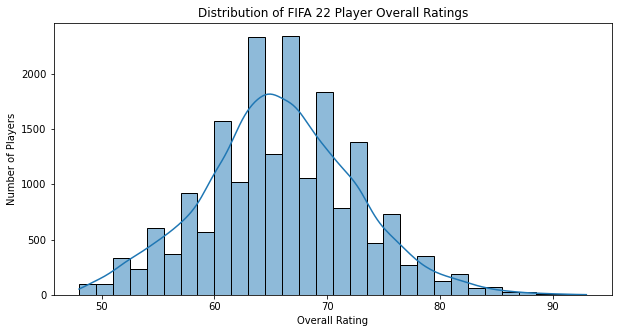

In [13]:
# Visualizing the distribution of player ratings
plt.figure(figsize=(10, 5))

sns.histplot(
    data=play_clean,
    x="Overall",
    bins=30,
    kde=True
)

plt.title("Distribution of FIFA 22 Player Overall Ratings")
plt.xlabel("Overall Rating")
plt.ylabel("Number of Players")

plt.show()

## 5. Feature Selection

We select player attributes that may influence the overall FIFA rating.
The target variable is Overall. Player identifiers, names, and
other rating-derived columns are excluded to reduce data leakage.

In [14]:
# Selecting relevant player attributes
features = [
    "Age", "Height", "Weight",
    "PaceTotal", "ShootingTotal", "PassingTotal",
    "DribblingTotal", "DefendingTotal", "PhysicalityTotal",
    "Crossing", "Finishing", "HeadingAccuracy",
    "ShortPassing", "Volleys", "Dribbling",
    "Curve", "FKAccuracy", "LongPassing",
    "BallControl", "Acceleration", "SprintSpeed",
    "Agility", "Reactions", "Balance",
    "ShotPower", "Jumping", "Stamina",
    "Strength", "LongShots", "Aggression",
    "Interceptions", "Positioning", "Vision",
    "Penalties", "Composure", "Marking",
    "StandingTackle", "SlidingTackle"
]

target = "Overall"

print("Number of selected features:", len(features))
print("Target variable:", target)

Number of selected features: 38
Target variable: Overall


In [15]:
# Checking selected feature availability
missing_features = [
    col for col in features
    if col not in play_clean.columns
]

print("Missing features:", missing_features)

Missing features: []


In [16]:
# Creating the dataset for machine learning
model_data = play_clean[features + [target]].copy()

print("Modeling dataset shape:", model_data.shape)

model_data.head()

Modeling dataset shape: (19156, 39)


,Age,Height,Weight,PaceTotal,ShootingTotal,PassingTotal,DribblingTotal,DefendingTotal,PhysicalityTotal,Crossing,...,Aggression,Interceptions,Positioning,Vision,Penalties,Composure,Marking,StandingTackle,SlidingTackle,Overall
0,34,170,72,85,92,91,95,34,65,85,...,44,40,93,95,75,96,20,35,24,93
1,32,185,81,78,92,79,85,44,82,71,...,81,49,95,81,90,88,35,42,19,92
2,36,187,83,87,94,80,87,34,75,87,...,63,29,95,76,88,95,24,32,24,91
3,22,182,73,97,88,80,92,36,77,78,...,62,38,92,82,79,88,26,34,32,91
4,28,188,87,87,92,78,90,52,90,13,...,34,19,11,65,11,68,27,12,18,91


In [17]:
# Checking missing values in the modeling dataset
model_data.isnull().sum()[model_data.isnull().sum() > 0]

Series([], dtype: int64)

## 6. Exploratory Data Analysis

In this section, we explore relationships between player attributes
and overall FIFA ratings. We examine feature correlations and
visualize important patterns in the dataset.

In [18]:
# Calculating correlations with overall rating
correlations = model_data.corr()["Overall"].drop("Overall")

correlations = correlations.sort_values(ascending=False)

print("Top 10 positively correlated features:")
print(correlations.head(10))

print("\nTop 10 negatively correlated features:")
print(correlations.tail(10))

Top 10 positively correlated features:
Reactions           0.870076
Composure           0.705302
PassingTotal        0.696286
DribblingTotal      0.652533
PhysicalityTotal    0.569496
ShotPower           0.556344
Vision              0.519104
ShortPassing        0.513861
LongPassing         0.494812
ShootingTotal       0.472543
Name: Overall, dtype: float64

Top 10 negatively correlated features:
Jumping           0.283754
Agility           0.267661
StandingTackle    0.257544
PaceTotal         0.242933
SlidingTackle     0.231777
SprintSpeed       0.204393
Acceleration      0.192796
Weight            0.146297
Balance           0.124327
Height            0.040772
Name: Overall, dtype: float64


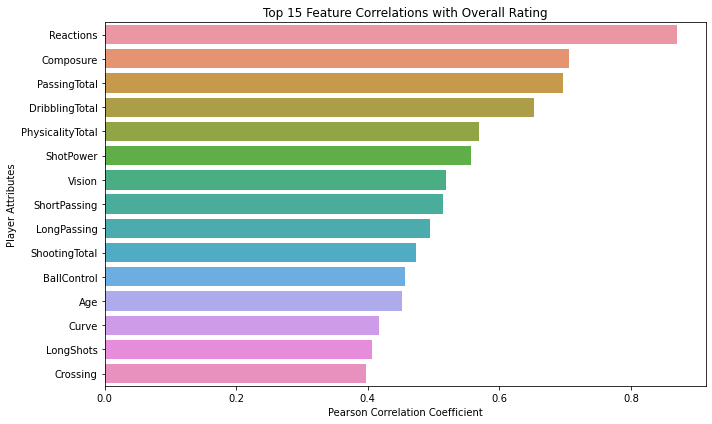

In [19]:
# Visualizing the strongest correlations with overall rating
top_features = correlations.abs().sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=correlations.loc[top_features.index].values,
    y=top_features.index
)

plt.title("Top 15 Feature Correlations with Overall Rating")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Player Attributes")

plt.tight_layout()
plt.show()

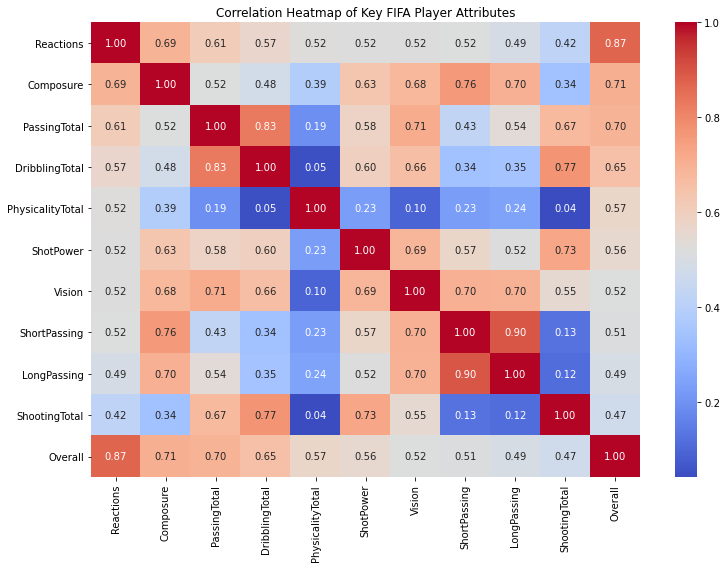

In [20]:
# Correlation heatmap for the top 10 related features
selected_cols = top_features.index[:10].tolist() + ["Overall"]

plt.figure(figsize=(11, 8))

sns.heatmap(
    model_data[selected_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap of Key FIFA Player Attributes")

plt.tight_layout()
plt.show()

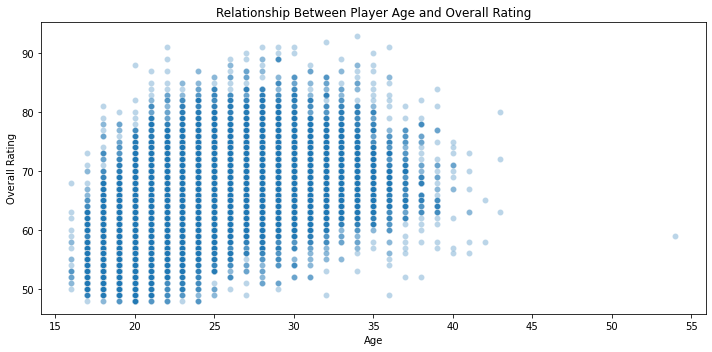

In [21]:
# Examining the relationship between age and overall rating
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=model_data,
    x="Age",
    y="Overall",
    alpha=0.3
)

plt.title("Relationship Between Player Age and Overall Rating")
plt.xlabel("Age")
plt.ylabel("Overall Rating")

plt.tight_layout()
plt.show()